In [13]:
import os
import pandas as pd 
import numpy as np
import warnings
from pathlib import Path
import json 

import matplotlib.pyplot as plt
from matplotlib_scalebar.scalebar import ScaleBar
from matplotlib.backends.backend_pdf import PdfPages
import seaborn as sns

from neuron_morphology.swc_io import morphology_from_swc
from morph_utils.visuals import basic_morph_plot
from morph_utils.measurements import leftextent, rightextent #cellwidth, downextent, upextent
from morph_utils.templates import load_layer_template 

import sys 
sys.path.append('/root/capsule/code/figures') 
from core_utils import get_seaad_colors, get_tx_order
from morphology_utils import add_swc_paths

In [14]:
viewer_type = 'axon' #dendrite, axon, both 
species = "human"


In [15]:
# Save root 
viewer_dir = Path('/root/capsule/scratch') / '20260722' /'viewers'
os.makedirs(viewer_dir, exist_ok=True)

viewer_outfile = viewer_dir / 'human_excitatory_page_viewer_{}_byTtype_bySomaDepth.pdf'.format(viewer_type)


class_col = 'class_label_Hierarchical'
subclass_col = 'subclass_label_Hierarchical'
cluster_col = 'cluster_label_Hierarchical'

# Data paths
DATA_ROOT = Path('/root/capsule/data')
metadata_path =              DATA_ROOT / 'human'            / 'metadata'   / '20260722' / 'human_metadata.csv'
morpho_data_dend_root =      DATA_ROOT / 'human' / 'morphology' / 'dendrite' / '20260712'
morpho_data_axon_root =      DATA_ROOT / 'human' / 'morphology' / 'axon'     / '20260715'
layer_aligned_dir =          DATA_ROOT / 'human' / 'morphology' / 'swc'      / '20260625' / 'SWC_LayerAligned'

l23_ttype_rename_file =       DATA_ROOT / 'formatting_dicts' / 'L23_ttype_rename.json'

# features_dend_path = morpho_data_dend_root / 'RawFeaturesWide.csv'
# features_axon_path = morpho_data_axon_root / 'RawFeaturesWide.csv'
soma_depths_dend_path = morpho_data_dend_root / 'AlignedSomaDepths.csv'
soma_depths_axon_path = morpho_data_axon_root / 'AlignedSomaDepths.csv'




In [16]:

# node types to plot i.e. [soma, axon, basal, apical] 
if viewer_type == 'both': compartment_list=[1,2,3,4]
elif viewer_type == 'axon': compartment_list=[1,2]
elif viewer_type == 'dendrite': compartment_list=[1,3,4] 

ttype_var_name = cluster_col
subclass_var_name = subclass_col
sort_by = [ttype_var_name, 'soma_distance_from_pia'] 
plot_view = 'xy' #'xy', 'yz', or 'both'
num_rows = 4

#optional 
title = ['specimen_id', 'structure'] 
title_font_size = [2,3] 

if plot_view == 'yz': set_side = [True]
elif plot_view == 'both': set_side = [False, True]
else: set_side = [False] #xy or other

Organize

In [17]:
# Load taxonomy dictionaries
with open(l23_ttype_rename_file, "r") as f:
    L23_rename_dict = json.load(f)

# Set some vars
cluster_var = sort_by[0]

# Get layer and color data
layer_info, layer_labels, layer_colors = load_layer_template(species)
color_dict = get_seaad_colors()


#load the cells
if viewer_type == 'dendrite':
    cells = pd.read_csv(soma_depths_dend_path, index_col='specimen_id')

elif viewer_type == 'axon' :
    cells = pd.read_csv(soma_depths_axon_path, index_col='specimen_id')

elif viewer_type == 'both':
    cells_dend = pd.read_csv(soma_depths_dend_path, index_col='specimen_id')
    cells_axon = pd.read_csv(soma_depths_axon_path, index_col='specimen_id')
    cells = cells_dend.loc[cells_dend.index.intersection(cells_axon.index)]
else:
    raise ValueError(f'Unknown viewer_type: {viewer_type}')

metadata = pd.read_csv(metadata_path, index_col='cell_id')
metadata = metadata.merge(cells, how='inner', left_index=True, right_index=True)

# Get layer aligned files
cells['specimen_id'] = cells.index
cells = add_swc_paths(cells, layer_aligned_dir, column_name='SWC_layer_aligned')

#map the normalized depth in pia to the average layer pia/wm values 
avg_pia = layer_info['1']
avg_wm = layer_info['wm']
metadata['depth_from_pia_norm_to_layers'] = metadata['depth_from_pia_norm'].apply(lambda x: x * (avg_wm - avg_pia) + avg_pia if pd.notnull(x) else np.nan)

# Get subclass/ttype order for sorting
ttype_order, subclass_order = get_tx_order() #cells, ttype_var_name)
cells = cells.merge(metadata[[ttype_var_name, subclass_var_name, 'structure']], how='left', left_index=True, right_index=True)
cells[ttype_var_name] = cells[ttype_var_name].replace(L23_rename_dict)
cells[ttype_var_name] = pd.Categorical(cells[ttype_var_name], categories=ttype_order, ordered=True)
cells[subclass_var_name] = pd.Categorical(cells[subclass_var_name], categories=subclass_order, ordered=True)

# Sort cells 
if all(item in list(cells.columns) for item in sort_by): #check if all items in sort_by are column names in cells 
    sorted_cells = cells.sort_values(by=sort_by)
else:
    print('Warning: cannot sort cells. Some value(s) in \'sort_by\' are not column names in input cell csv. Plotting unsorted cells.')
    sorted_cells = cells


Plot

Sps list is 193 long


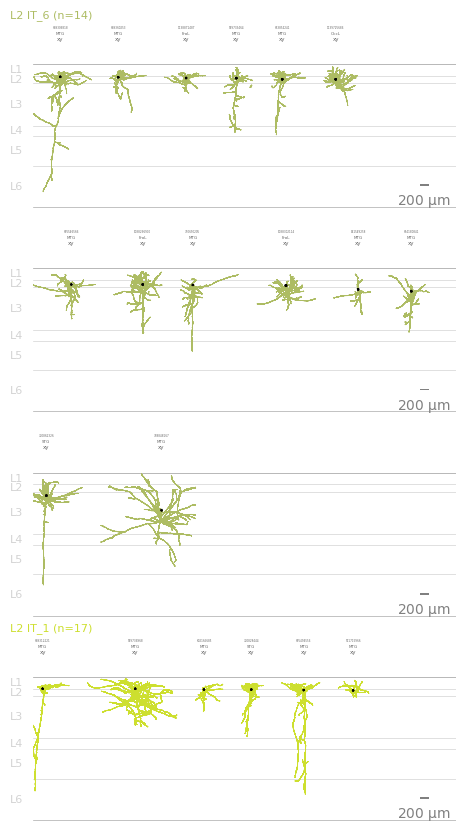

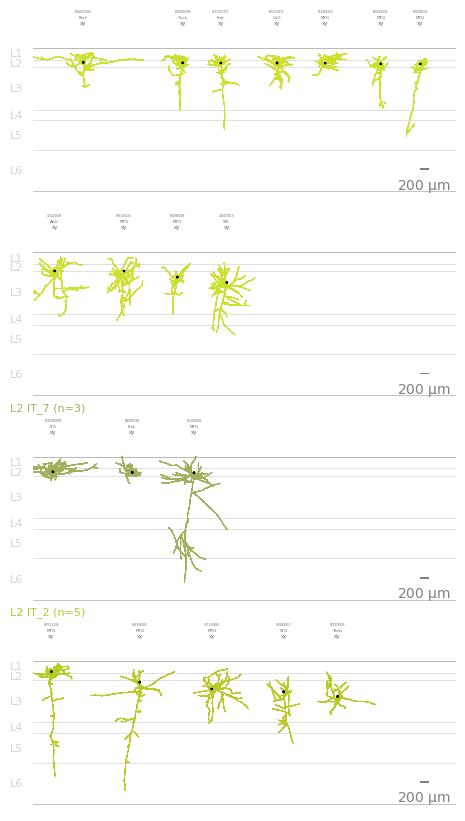

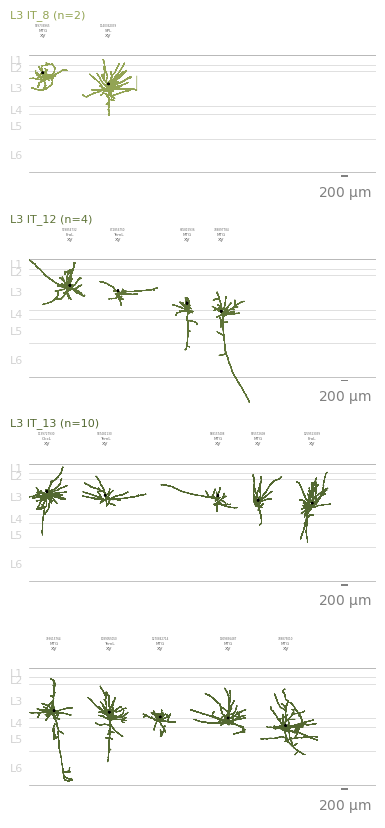

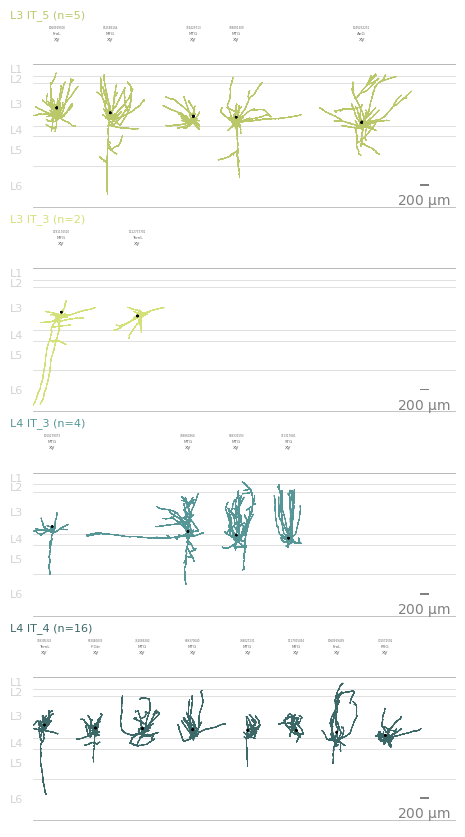

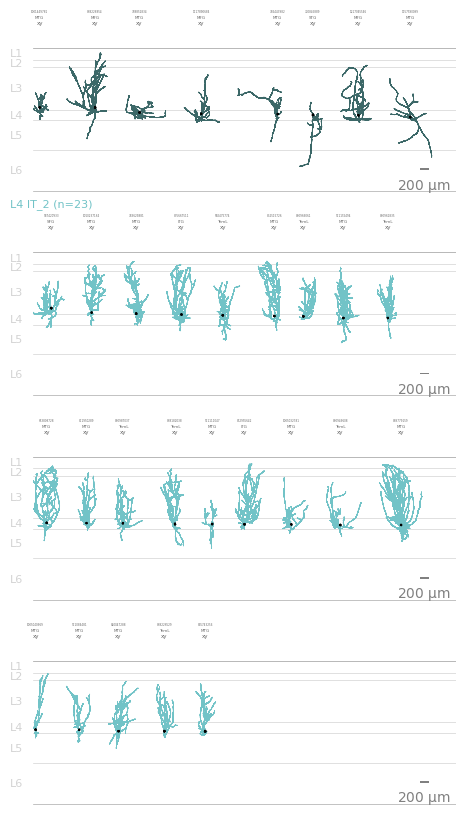

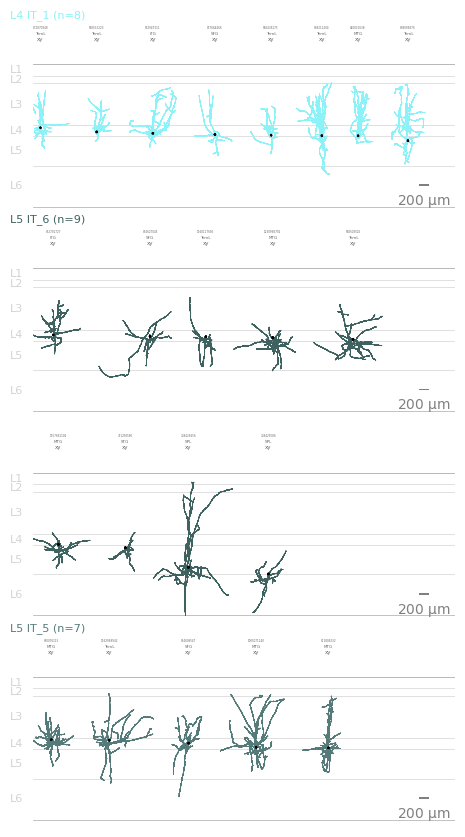

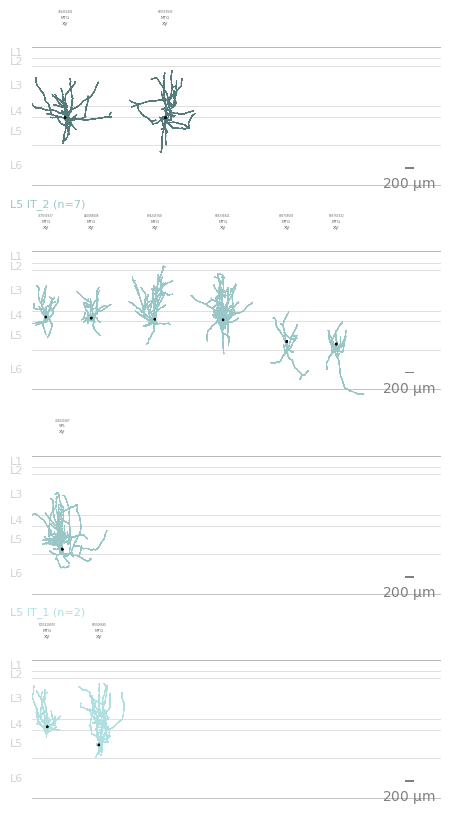

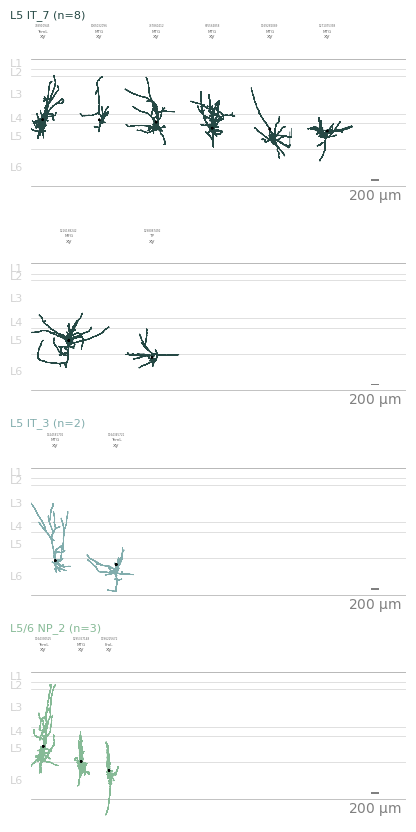

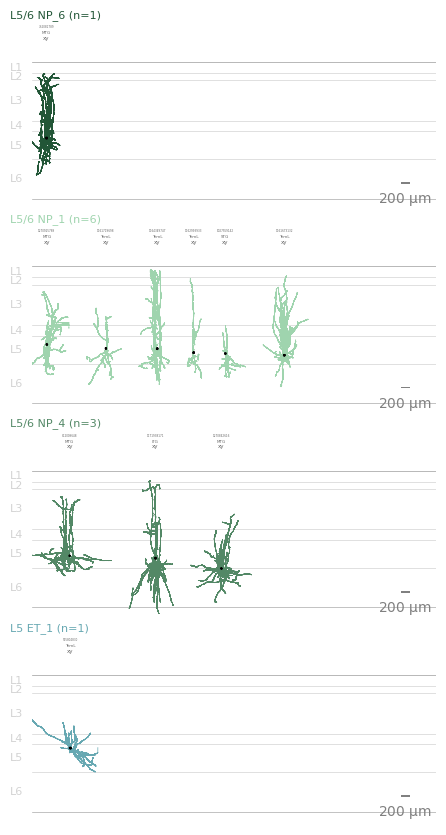

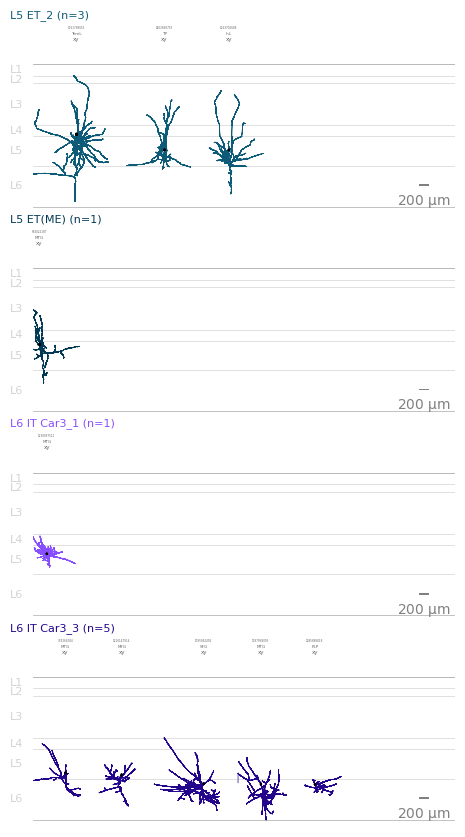

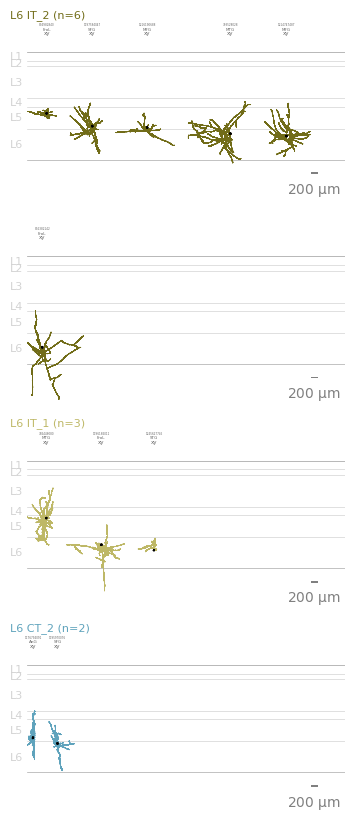

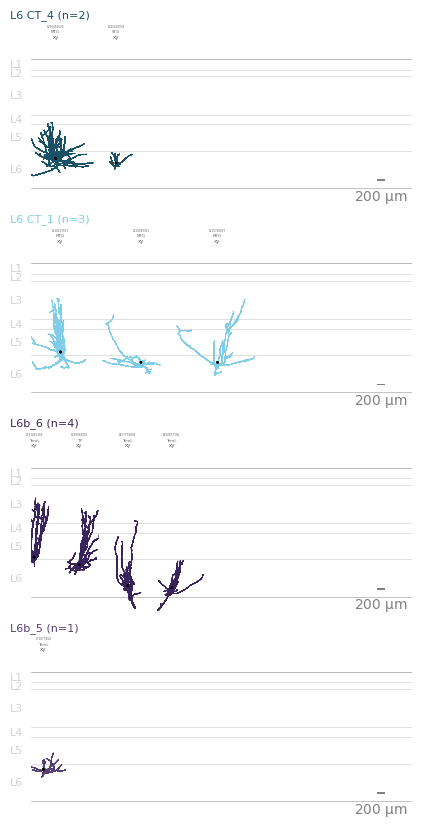

<Figure size 640x480 with 0 Axes>

In [18]:
#make pdf viewer

#formatting vars for tinkering 
group_title_start_height = 1000 #900 #starting height for group (e.g., region) title 
group_title_font_size = 8 #font size for group (e.g., region) title 

cell_title_start_height = 900 #700 #starting height for cell title 
cell_title_vertical_space = 130 #150 #how much white space between rows of the cell title
cell_title_view_font_size = 4 #font size for cell 'xy', 'yz' view label

#####

with warnings.catch_warnings():
    warnings.simplefilter(action='ignore', category=FutureWarning)

    sps_list = list(sorted_cells.specimen_id.values)
    sps_list.reverse() #because we pop() off spc, which takes off the last value in the list. Reversing here keeps the plotting order consistent with the csv order.

    clust_id_set = set()
    failed_to_load = []

    print("Sps list is {} long".format(len(sps_list)))
    buffer=400
    with PdfPages(viewer_outfile) as pdf:
        while sps_list != []:
            fig, axes = plt.subplots(nrows=num_rows,ncols=1,figsize=(7.5,10),sharex=True,sharey=True, gridspec_kw = {'wspace':0, 'hspace':0.3}) 
            for ax in axes: 

                ax.axis('off')
                ax.set_xlim(0,9100) 
                lim = 9000
                xloc = 0
                xoffset = 0
                ax.set_anchor('W')
                ax.axhline(0, c="lightgrey",linewidth=0.50)

                # Plot layers with labels 
                for l in layer_info:
                    ax.axhline(-layer_info[l], c=layer_colors[l],linewidth=0.50)
                for l in layer_labels:
                    ax.text(-500,-layer_labels[l], "{}".format(l),verticalalignment='center', horizontalalignment='left',fontsize=group_title_font_size, color='lightgrey') 
                
                while xloc < lim: #plot as many neurons as fit on this row
                    if sps_list != []:
                        sp = sps_list.pop() 
                        
                        # get data for this specimen
                        ttype = sorted_cells[sorted_cells.specimen_id==sp][ttype_var_name].iloc[0]
                        clust_id = sorted_cells[sorted_cells.specimen_id==sp][cluster_var].iloc[0]
                        clust_len = len(sorted_cells[sorted_cells[cluster_var]==clust_id])

                        # cell title
                        sp_title = []
                        if 'title' in locals():
                            for t in title:
                                sp_title.append(str(sorted_cells[sorted_cells.specimen_id==sp][t].iloc[0]))
                        
                        # get plotting colors 
                        try:
                            # decide the colors for this cells axon, apical, and basal
                            hex_color = color_dict[ttype][1:]

                            contrast_level = 0.45
                            lighter_color_rgb = tuple(int(hex_color[i:i+2], 16) for i in (0, 2, 4))
                            darker_color_rgb = tuple([int((contrast_level*x)) for x in lighter_color_rgb])
                            grey_hex = '#8f8f8f'
                            dark_hex = '#%02x%02x%02x' % darker_color_rgb
                            hex_color = '#'+hex_color

                            cell_type_colors_dict = {3: dark_hex, 4: hex_color, 2: grey_hex}

                            #swap colors for axon-only plotting
                            if compartment_list == [1,2]: 
                                cell_type_colors_dict = {3: grey_hex, 4: grey_hex, 2: hex_color}
                        except: 
                            cell_type_colors_dict={1: 'black', 2: "firebrick", 4: "orange", 3: "steelblue"}
                        morph_colors = {k:v for k,v in cell_type_colors_dict.items() if k in compartment_list}
                        
                        # get the layer-aligned file
                        swc_pth = sorted_cells.SWC_layer_aligned[sorted_cells.specimen_id == sp].iloc[0]
                        nrn = morphology_from_swc(swc_pth)

                        xoffset += leftextent(nrn,compartment_list)
                        if clust_id not in clust_id_set:
                            if xloc != 0:
                                sps_list = sps_list + [sp]
                                break

                            else:
                                #plot cell title
                                y = cell_title_start_height
                                i = 0
                                for l in sp_title:
                                    y-=cell_title_vertical_space
                                    ax.text(xoffset, y,l,horizontalalignment='center',fontsize=title_font_size[i], color="dimgrey")
                                    i+=1
                                    
                                #plot cell cluster info (e.g. ttype and num cells)
                                ax.text(-500,group_title_start_height,
                                "{} (n={}) ".format(clust_id,clust_len),
                                horizontalalignment='left',fontsize=group_title_font_size, color=hex_color) 

                                clust_id_set.add(clust_id)

                                y-=cell_title_vertical_space
                                for s in set_side:
                                    if s: v = 'yz'
                                    else: v = 'xy'
                                    ax.text(xoffset,y,v,horizontalalignment='center',fontsize=cell_title_view_font_size, color="dimgrey")

                                    basic_morph_plot(nrn, morph_colors = morph_colors, ax = ax, xoffset = xoffset, side = s,
                                                     scatter_roots = False, scatter_soma = False, plot_soma = True)
                                    xoffset += rightextent(nrn,compartment_list)
                                    xoffset += buffer       

                        else:
                            if xoffset+rightextent(nrn,compartment_list)+buffer>lim: #if gone over page width limit for this row, pop cell back on list and go to next plotting row
                                sps_list = sps_list + [sp]
                                break
                            else:
                                
                                clust_id_set.add(clust_id)
                                y = cell_title_start_height #plot cell title 
                                i = 0
                                for l in sp_title:
                                    y-=cell_title_vertical_space
                                    ax.text(xoffset, y,l,horizontalalignment='center',fontsize=title_font_size[i], color="dimgrey")
                                    i+=1

                                y-=cell_title_vertical_space
                                for s in set_side:
                                    if s: v = 'yz'
                                    else: v = 'xy'
                                    ax.text(xoffset,y,v,horizontalalignment='center',fontsize=cell_title_view_font_size, color="dimgrey")

                                    basic_morph_plot(nrn, morph_colors = morph_colors, ax = ax, xoffset = xoffset, side = s,
                                                     scatter_roots = False, scatter_soma = False, plot_soma = True)
                                    xoffset += rightextent(nrn,compartment_list)
                                    xoffset += buffer

                        if xloc == 0:
                             #add a scale bar 
                            scalebar = ScaleBar(1, "um", location='lower right', frameon=False, length_fraction=0.05, color='grey')
                            ax.add_artist(scalebar)

                        xloc=xoffset


                    else:
                        break

            for ax in axes:
                ax.set_aspect("equal")
            fig.subplots_adjust(wspace=0, hspace=0.0)
            pdf.savefig(dpi=600)
    plt.show()
    plt.clf()
    print()
